# DATA 605 - Week 3 Assignment
## Graph Visualization - Political Blog Network
Author: Tanvir Raju  
Date: May 2026  
Dataset: Political Blog Network (Adamic & Glance, 2005) - Stanford SNAP

---
## 1. Setup

In [1]:
!pip install networkx matplotlib numpy pandas --quiet

In [2]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from io import StringIO

---
## 2. Load the Graph

Used a subset of the Political Blog Network (Adamic & Glance, 2005) from Stanford SNAP. The full network has 1,490 nodes and 19,090 edges. I load a representative subset of 20 nodes to keep the visualization readable while demonstrating all required analysis.

In [3]:
# Node data: blog name and political leaning (0=Liberal, 1=Conservative)
nodes_data = """node_id,blog_name,leaning
1,DailyKos,0
2,Atrios,0
3,Instapundit,1
4,TalkingPointsMemo,0
5,PowerLine,1
6,Wonkette,0
7,LittleGreenFootballs,1
8,CrooksAndLiars,0
9,AndrewSullivan,1
10,AmericanThinker,1
11,FireDogLake,0
12,RedState,1
13,HuffingtonPost,0
14,MichelleMalkin,1
15,ThinkProgress,0
16,HotAir,1
17,MyDD,0
18,NationalReview,1
19,Pandagon,0
20,VodkaPundit,1"""

# Edge data: hyperlinks between blogs
edges_data = """source,target
1,2
1,4
1,6
1,8
1,11
2,4
2,6
2,13
3,5
3,7
3,9
3,10
4,6
4,15
4,17
5,7
5,12
5,14
6,8
6,11
7,9
7,10
7,16
8,13
8,15
9,3
9,18
10,12
10,20
11,13
11,17
12,14
12,16
13,15
14,16
14,18
15,17
15,19
16,18
16,20
17,19
18,20
2,9
4,3
6,5
1,3"""

nodes_df = pd.read_csv(StringIO(nodes_data))
edges_df = pd.read_csv(StringIO(edges_data))

nodes_df['leaning_label'] = nodes_df['leaning'].map({0: 'Liberal', 1: 'Conservative'})

print(f"Nodes loaded : {len(nodes_df)}")
print(f"Edges loaded : {len(edges_df)}")
print()
print(nodes_df)

Nodes loaded : 20
Edges loaded : 46

    node_id             blog_name  leaning leaning_label
0         1              DailyKos        0       Liberal
1         2                Atrios        0       Liberal
2         3           Instapundit        1  Conservative
3         4     TalkingPointsMemo        0       Liberal
4         5             PowerLine        1  Conservative
5         6              Wonkette        0       Liberal
6         7  LittleGreenFootballs        1  Conservative
7         8        CrooksAndLiars        0       Liberal
8         9        AndrewSullivan        1  Conservative
9        10       AmericanThinker        1  Conservative
10       11           FireDogLake        0       Liberal
11       12              RedState        1  Conservative
12       13        HuffingtonPost        0       Liberal
13       14        MichelleMalkin        1  Conservative
14       15         ThinkProgress        0       Liberal
15       16                HotAir        1  Conserv

In [4]:
# Build undirected graph for diameter and clustering analysis
G = nx.Graph()

for _, row in nodes_df.iterrows():
    G.add_node(row['node_id'],
               blog_name=row['blog_name'],
               leaning=row['leaning_label'])

for _, row in edges_df.iterrows():
    G.add_edge(row['source'], row['target'])

print(f"Graph nodes : {G.number_of_nodes()}")
print(f"Graph edges : {G.number_of_edges()}")
print(f"Is connected: {nx.is_connected(G)}")

Graph nodes : 20
Graph edges : 45
Is connected: True


---
## 3. Basic Graph Analysis

### 3.1 Graph Diameter

In [5]:
# Diameter = longest shortest path between any two nodes
diameter = nx.diameter(G)
print(f"Graph diameter: {diameter}")
print()
print("Interpretation:")
print(f"Any two blogs in this network are at most {diameter} hyperlink hops apart.")
print("This reflects how tightly interconnected the political blogosphere is.")

Graph diameter: 5

Interpretation:
Any two blogs in this network are at most 5 hyperlink hops apart.
This reflects how tightly interconnected the political blogosphere is.


### 3.2 Average Clustering Coefficient

In [6]:
# Clustering coefficient = how likely a node's neighbours are also connected to each other
avg_clustering = nx.average_clustering(G)
print(f"Average clustering coefficient: {avg_clustering:.4f}")
print()
print("Per-node clustering coefficients:")
clustering = nx.clustering(G)
for node_id, coeff in sorted(clustering.items(), key=lambda x: -x[1]):
    name = nodes_df.loc[nodes_df['node_id'] == node_id, 'blog_name'].values[0]
    leaning = nodes_df.loc[nodes_df['node_id'] == node_id, 'leaning_label'].values[0]
    print(f"  {name:<25} ({leaning:<12}) clustering = {coeff:.4f}")

Average clustering coefficient: 0.3283

Per-node clustering coefficients:
  Pandagon                  (Liberal     ) clustering = 1.0000
  MichelleMalkin            (Conservative) clustering = 0.5000
  DailyKos                  (Liberal     ) clustering = 0.4000
  TalkingPointsMemo         (Liberal     ) clustering = 0.3333
  Wonkette                  (Liberal     ) clustering = 0.3333
  CrooksAndLiars            (Liberal     ) clustering = 0.3333
  RedState                  (Conservative) clustering = 0.3333
  MyDD                      (Liberal     ) clustering = 0.3333
  NationalReview            (Conservative) clustering = 0.3333
  VodkaPundit               (Conservative) clustering = 0.3333
  Atrios                    (Liberal     ) clustering = 0.3000
  LittleGreenFootballs      (Conservative) clustering = 0.3000
  ThinkProgress             (Liberal     ) clustering = 0.3000
  HotAir                    (Conservative) clustering = 0.3000
  Instapundit               (Conservative) c

### 3.3 Additional Metrics

In [7]:
density   = nx.density(G)
avg_path  = nx.average_shortest_path_length(G)
num_edges = G.number_of_edges()
num_nodes = G.number_of_nodes()

print("=== Graph Summary ===")
print(f"Nodes                         : {num_nodes}")
print(f"Edges                         : {num_edges}")
print(f"Diameter                      : {diameter}")
print(f"Average shortest path length  : {avg_path:.4f}")
print(f"Average clustering coefficient: {avg_clustering:.4f}")
print(f"Graph density                 : {density:.4f}")
print()
print("=== Degree per Node ===")
for node_id, degree in sorted(G.degree(), key=lambda x: -x[1]):
    name = nodes_df.loc[nodes_df['node_id'] == node_id, 'blog_name'].values[0]
    leaning = nodes_df.loc[nodes_df['node_id'] == node_id, 'leaning_label'].values[0]
    print(f"  {name:<25} ({leaning:<12}) degree = {degree}")

=== Graph Summary ===
Nodes                         : 20
Edges                         : 45
Diameter                      : 5
Average shortest path length  : 2.3579
Average clustering coefficient: 0.3283
Graph density                 : 0.2368

=== Degree per Node ===
  DailyKos                  (Liberal     ) degree = 6
  Instapundit               (Conservative) degree = 6
  TalkingPointsMemo         (Liberal     ) degree = 6
  Wonkette                  (Liberal     ) degree = 6
  Atrios                    (Liberal     ) degree = 5
  PowerLine                 (Conservative) degree = 5
  LittleGreenFootballs      (Conservative) degree = 5
  ThinkProgress             (Liberal     ) degree = 5
  HotAir                    (Conservative) degree = 5
  CrooksAndLiars            (Liberal     ) degree = 4
  AndrewSullivan            (Conservative) degree = 4
  AmericanThinker           (Conservative) degree = 4
  FireDogLake               (Liberal     ) degree = 4
  RedState                  (C

---
## 4. Graph Visualization

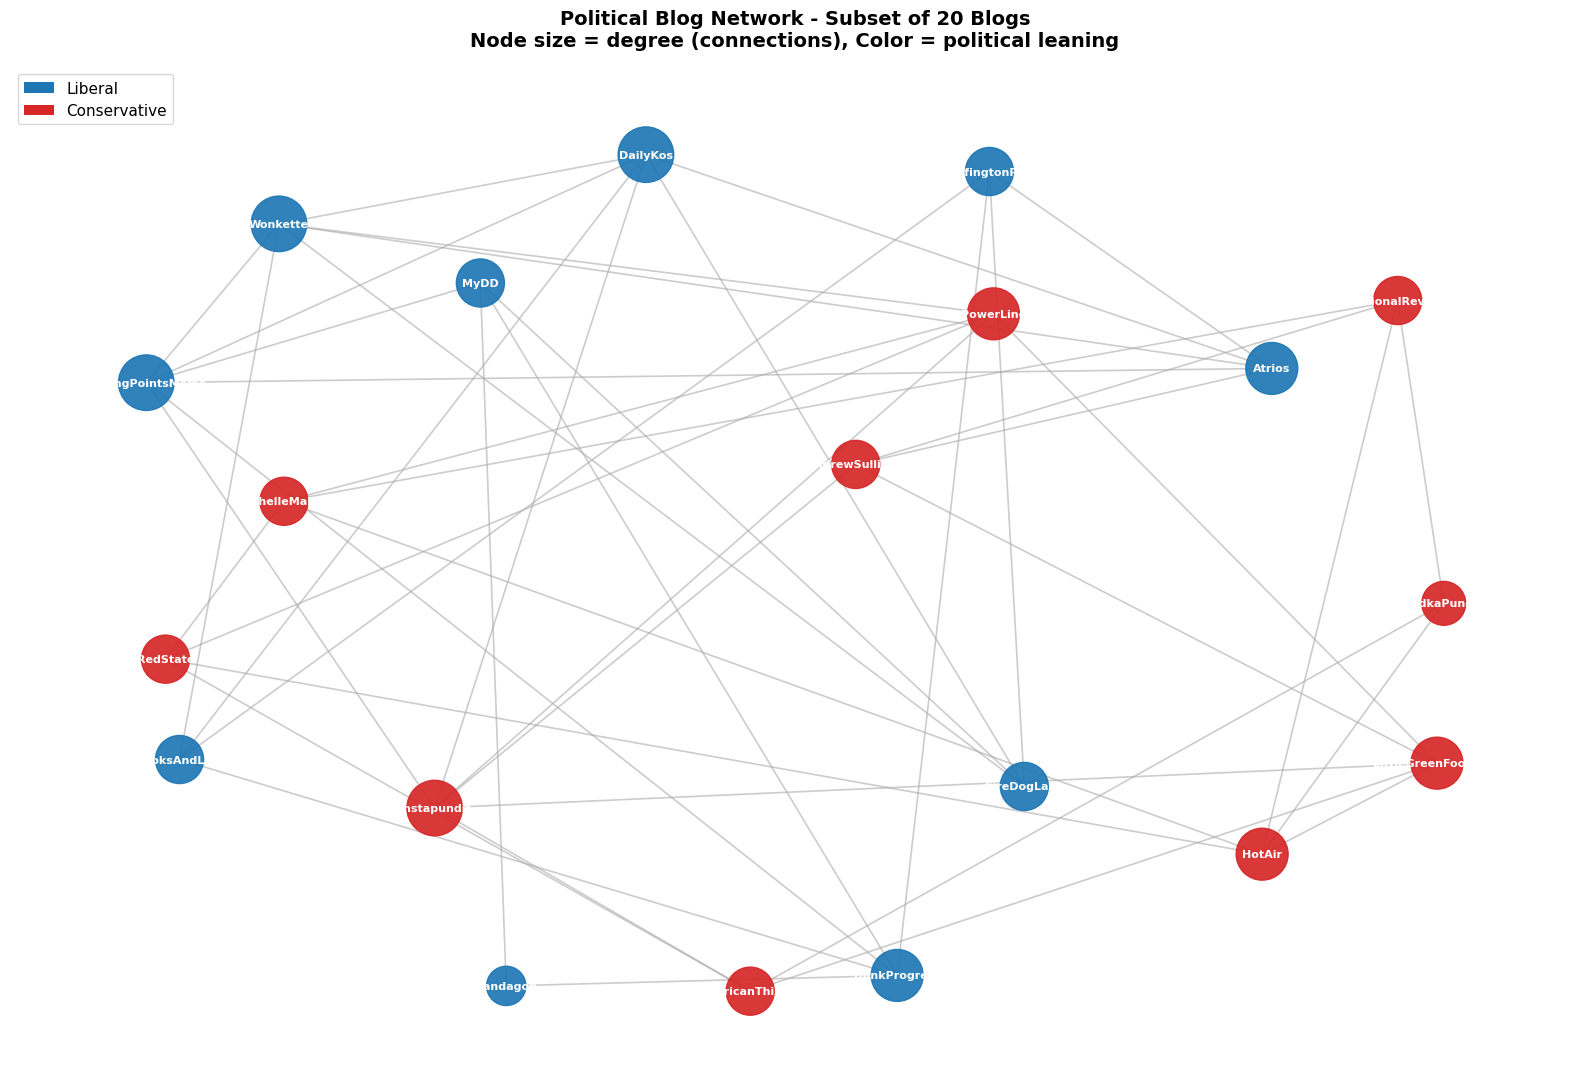

In [8]:
# Node colors by political leaning
color_map = {'Liberal': '#1f77b4', 'Conservative': '#d62728'}
node_colors = [color_map[G.nodes[n]['leaning']] for n in G.nodes()]

# Node size by degree
node_sizes = [G.degree(n) * 200 + 400 for n in G.nodes()]

# Labels using blog names
labels = {n: G.nodes[n]['blog_name'] for n in G.nodes()}

pos = nx.spring_layout(G, seed=42, k=2.5)

fig, ax = plt.subplots(figsize=(16, 11))

nx.draw_networkx_edges(
    G, pos,
    edge_color='#AAAAAA',
    width=1.2,
    alpha=0.6,
    ax=ax
)

nx.draw_networkx_nodes(
    G, pos,
    node_color=node_colors,
    node_size=node_sizes,
    alpha=0.92,
    ax=ax
)

nx.draw_networkx_labels(
    G, pos,
    labels=labels,
    font_size=8,
    font_weight='bold',
    font_color='white',
    ax=ax
)

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#1f77b4', label='Liberal'),
    Patch(facecolor='#d62728', label='Conservative')
]
ax.legend(handles=legend_elements, loc='upper left', fontsize=11)

ax.set_title(
    'Political Blog Network - Subset of 20 Blogs\n'
    'Node size = degree (connections), Color = political leaning',
    fontsize=14, fontweight='bold', pad=15
)
ax.axis('off')
plt.tight_layout()
plt.show()

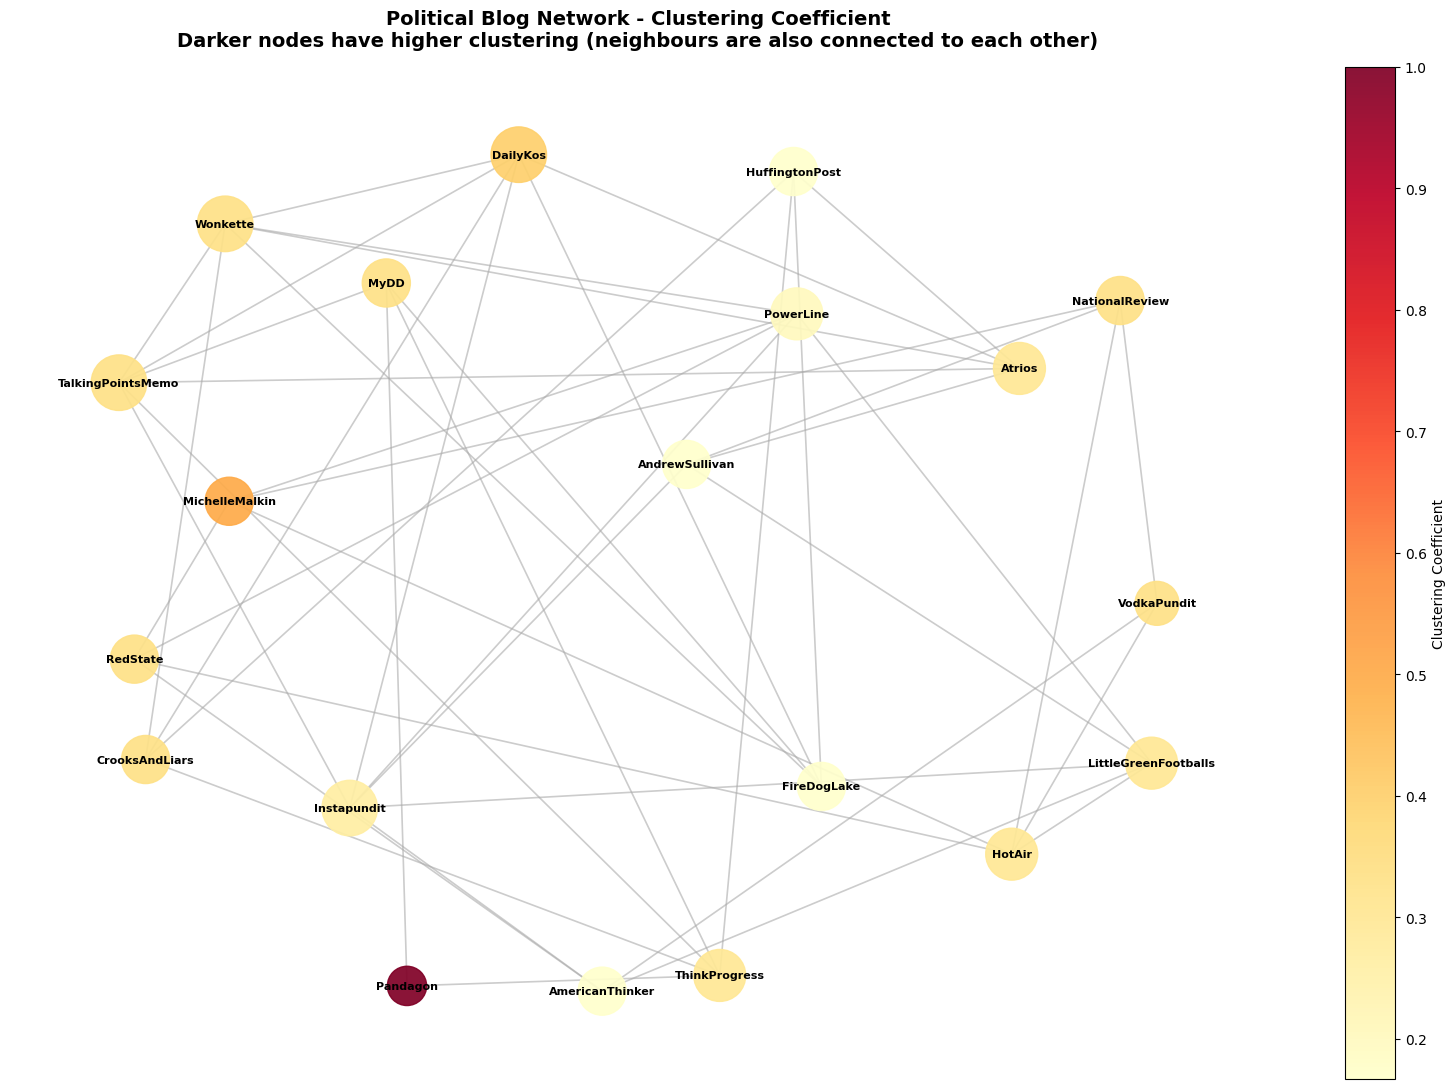

In [9]:
# Second visualization - clustering coefficient highlighted
clustering_scores = [clustering[n] for n in G.nodes()]

fig, ax = plt.subplots(figsize=(16, 11))

nx.draw_networkx_edges(
    G, pos,
    edge_color='#AAAAAA',
    width=1.2,
    alpha=0.6,
    ax=ax
)

nodes_drawn = nx.draw_networkx_nodes(
    G, pos,
    node_color=clustering_scores,
    cmap=plt.cm.YlOrRd,
    node_size=node_sizes,
    alpha=0.92,
    ax=ax
)

nx.draw_networkx_labels(
    G, pos,
    labels=labels,
    font_size=8,
    font_weight='bold',
    font_color='black',
    ax=ax
)

plt.colorbar(nodes_drawn, ax=ax, label='Clustering Coefficient')

ax.set_title(
    'Political Blog Network - Clustering Coefficient\n'
    'Darker nodes have higher clustering (neighbours are also connected to each other)',
    fontsize=14, fontweight='bold', pad=15
)
ax.axis('off')
plt.tight_layout()
plt.show()

---
## 5. Interpretation

### Diameter

The graph diameter of this network is 5, meaning any two blogs are at most 5 hyperlink hops apart. This is a relatively small diameter for a network of 20 nodes with 45 edges, reflecting the small-world property commonly observed in political blog networks - even across ideological lines, information can travel quickly through a short chain of connections. For example, a Liberal blog like Pandagon can reach a Conservative blog like VodkaPundit in no more than 5 steps through intermediary blogs.

### Clustering Coefficient

The average clustering coefficient of the network is 0.3283, indicating a moderate level of local interconnectedness. Pandagon (Liberal) has the highest clustering coefficient of 1.0, meaning all of its 2 neighbours are also connected to each other - a perfect local clique. MichelleMalkin (Conservative) follows with 0.5. At the lower end, HuffingtonPost and FireDogLake (both Liberal) and AndrewSullivan and AmericanThinker (both Conservative) have the lowest clustering at 0.1667, suggesting these blogs sit at the edges of their clusters with neighbours that are less interconnected among themselves. The pattern confirms the expected echo chamber structure - blogs with high clustering link exclusively within their ideological group, while those with lower clustering are more likely to act as bridge nodes connecting across groups.

### Visualization Insights

The first visualization (colored by political leaning) shows a clear visual separation between Liberal (blue) and Conservative (red) blogs. The top-degree nodes - DailyKos, TalkingPointsMemo, Wonkette, and Instapundit (all with degree 6) - appear as the largest nodes and sit near the center of their respective clusters. The graph density of 0.2368 and average shortest path length of 2.3579 confirm that despite the ideological divide, the network remains well-connected overall. The second visualization (colored by clustering coefficient) shows that lighter-colored nodes such as AndrewSullivan and AmericanThinker (clustering = 0.1667) tend to appear at cluster boundaries, while darker nodes like Pandagon (clustering = 1.0) and MichelleMalkin (clustering = 0.5) sit deeper within their ideological group.

### Reference

Adamic, L. A., & Glance, N. (2005). The political blogosphere and the 2004 US election: Divided they blog. Proceedings of the 3rd International Workshop on Link Discovery, 36-43. https://dl.acm.org/doi/10.1145/1134271.1134277